# Lab 4 — Build the Audience, Then Buy It
Name: Adelina Khitrenko | Group: KM-43

## Setup

In [1]:
%pip -q install --disable-pip-version-check kagglehub pyarrow jinja2

In [2]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab4-tv-audiences/versions/2")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")
survey = pd.read_csv(f"{DATA}/purchase_survey.txt", sep="\t", dtype=str,
                     keep_default_na=False)
survey_layout = pd.read_csv(f"{DATA}/purchase_survey_layout.txt", sep="\t",
                            dtype=str, keep_default_na=False)
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")
universe = pd.read_parquet(f"{DATA}/universe.parquet")

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False,
                     "axes.spines.right": False})

programs["broadcast_date"] = pd.to_datetime(programs["broadcast_date"])
daily_weights["broadcast_date"] = pd.to_datetime(daily_weights["broadcast_date"])
days = pd.date_range("2024-10-01", "2024-10-31")

person_ids = viewer_attributes.loc[
    viewer_attributes.attr_id.isin([101, 102]), "respondent_id"]
people = pd.DataFrame(index=pd.Index(person_ids, name="respondent_id"))
age = viewer_attributes.loc[viewer_attributes.attr_id.eq(300)]
people["age"] = age.set_index("respondent_id")["value"]
male_ids = viewer_attributes.loc[viewer_attributes.attr_id.eq(201), "respondent_id"]
people["sex"] = np.where(people.index.isin(male_ids), "Male", "Female")
adults = people.loc[people.age.ge(18)].copy()
print("Dataset version:", 2)

Using Colab cache for faster access to the 'adtech-lab4-tv-audiences' dataset.
Dataset version: 2


## Task 1.0 — Clean the survey file

In [3]:
# Look at the raw strings before changing anything.
display(survey.head(8))
display(survey_layout.loc[survey_layout.RECTYPE.eq("B"),
                          ["KEYWORD", "Text", "SAMPLE"]])

,RESPID,KEYWORD,VALUE
0,10415501,X710298,1
1,10072201,x710100,1
2,10302802,X710299,1
3,10070002,X710100,1
4,10130702,X710203,1
5,10243701,X710100,1
6,10342601,X710103,0
7,10399201,X710298,1


,KEYWORD,Text,SAMPLE
2,X710100,Any,4779
3,X710101,1 pair,1810
4,X710102,2 pairs,1308
5,X710103,3 or more pairs,1661
7,X710201,STRIDE,1563
8,X710202,KESTREL,354
9,X710203,EASYWALK,1050
10,X710298,OTHER BRAND,2739
11,X710299,DON'T KNOW,371


In [4]:
s = survey.copy()
audit = []
def record(kind, rows, action):
    audit.append({"Bad record": kind, "Rows": int(rows), "Action": action})

space = s.ne(s.apply(lambda col: col.str.strip())).any(axis=1)
record("Extra spaces", space.sum(), "Strip text fields")
s = s.apply(lambda col: col.str.strip())
lower_codes = s.KEYWORD.ne(s.KEYWORD.str.upper())
record("Lowercase keywords", lower_codes.sum(), "Convert keywords to uppercase")
s["KEYWORD"] = s.KEYWORD.str.upper()

header = s.RESPID.eq("RESPID") & s.KEYWORD.eq("KEYWORD")
footer = s.RESPID.str.startswith("TOTAL ROWS:")
record("Repeated header", header.sum(), "Drop")
record("Footer", footer.sum(), "Drop")
s = s.loc[~(header | footer)].copy()

id_format = s.RESPID.str.fullmatch(r"\d+(?:\.0)?")
record("Invalid ID syntax", (~id_format).sum(), "Drop")
s = s.loc[id_format].copy()
decimal_ids = s.RESPID.str.endswith(".0")
zero_ids = s.RESPID.str.match(r"^0\d")
record("IDs ending in .0", decimal_ids.sum(), "Remove .0 and convert to integer")
record("IDs with leading zeros", zero_ids.sum(), "Convert to integer")
s["respondent_id"] = s.RESPID.str.replace(r"\.0$", "", regex=True).astype("int64")

is_adult = s.respondent_id.isin(adults.index)
household_ids = viewer_attributes.loc[viewer_attributes.attr_id.eq(104), "respondent_id"]
record("Household ID instead of a person", s.respondent_id.isin(household_ids).sum(), "Drop")
record("Panel member aged under 18", s.respondent_id.isin(people.index[people.age.lt(18)]).sum(), "Drop")
known_ids = pd.Index(viewer_attributes.respondent_id.unique())
record("ID outside the panel", (~s.respondent_id.isin(known_ids)).sum(), "Drop")
s = s.loc[is_adult].copy()
answer_layout = survey_layout.loc[survey_layout.RECTYPE.eq("B")].copy()
valid_code = s.KEYWORD.isin(answer_layout.KEYWORD)
record("Code outside this layout", (~valid_code).sum(), "Drop")
s = s.loc[valid_code].copy()

yes_values = ["1", "1.0", "Y", "YES", "TRUE"]
is_yes = s.VALUE.str.upper().isin(yes_values)
record("No/blank VALUE", (~is_yes).sum(), "Drop: not a yes answer")
record("Alternative yes format", (is_yes & s.VALUE.ne("1")).sum(), "Convert to 1")
s = s.loc[is_yes].copy()
s["VALUE"] = "1"
duplicates = s.duplicated(["respondent_id", "KEYWORD"])
record("Duplicate person-keyword yes", duplicates.sum(), "Keep one")
s = s.loc[~duplicates].copy()

In [5]:
pair_codes = {"X710101": 1, "X710102": 2, "X710103": 3}
pair_rows = s.loc[s.KEYWORD.isin(pair_codes)].copy()
pair_rows["pair_number"] = pair_rows.KEYWORD.map(pair_codes)
pair_count = pair_rows.groupby("respondent_id").KEYWORD.nunique()
two_pairs = int(pair_count.gt(1).sum())
best_pair = pair_rows.groupby("respondent_id").pair_number.max()
lower_pair = s.KEYWORD.isin(pair_codes) & (
    s.KEYWORD.map(pair_codes) < s.respondent_id.map(best_pair))
record("Conflicting lower pair count", lower_pair.sum(), "Drop lower count; keep higher")
s = s.loc[~lower_pair].copy()

# Any valid purchase answer means the person is a buyer.
buyer_ids = pd.Index(s.respondent_id.unique())
any_ids = s.loc[s.KEYWORD.eq("X710100"), "respondent_id"]
missing_any = buyer_ids.difference(any_ids)
record("Buyer without Any answer", len(missing_any), "Infer and add Any = yes")
s = pd.concat([s[["respondent_id", "KEYWORD", "VALUE"]],
               pd.DataFrame({"respondent_id": missing_any,
                             "KEYWORD": "X710100", "VALUE": "1"})], ignore_index=True)

flags = pd.crosstab(s.respondent_id, s.KEYWORD).gt(0)
purchases = pd.DataFrame(index=adults.index)
purchases["buyer"] = purchases.index.isin(buyer_ids)
purchases["pairs"] = best_pair.reindex(purchases.index).fillna(0).astype(int).replace({3: "3+"})
for brand, keyword in {"STRIDE": "X710201", "KESTREL": "X710202", "EASYWALK": "X710203"}.items():
    purchases[brand] = flags[keyword].reindex(purchases.index, fill_value=False)

check = answer_layout[["KEYWORD", "Text", "SAMPLE"]].copy()
check["SAMPLE"] = check.SAMPLE.astype(int)
check["My count"] = check.KEYWORD.map(s.groupby("KEYWORD").respondent_id.nunique()).fillna(0).astype(int)
check["Difference"] = check["My count"] - check.SAMPLE

In [6]:
print("Survey data rows:", len(survey))
print("Clean yes answers:", len(s))
print("Adult panel members:", len(adults))
print("Non-buyers:", int((~purchases.buyer).sum()))
print("People with two pair counts:", two_pairs)
display(pd.DataFrame(audit).query("Rows > 0").reset_index(drop=True))
display(check[["KEYWORD", "Text", "My count", "SAMPLE", "Difference"]])
display(purchases.head())
assert check.Difference.eq(0).all()
assert purchases.index.is_unique and len(purchases) == len(adults)

# Define the naive comparison explicitly: exact codes, exact VALUE=1,
# distinct raw IDs, and Any alone as the buyer flag, with no cleaning.
raw_kestrel = survey.loc[survey.KEYWORD.eq("X710202") & survey.VALUE.eq("1"), "RESPID"].nunique()
raw_buyer_ids = survey.loc[survey.KEYWORD.eq("X710100") & survey.VALUE.eq("1"), "RESPID"].nunique()
raw_buyer_share = raw_buyer_ids / len(adults)
clean_buyer_share = purchases.buyer.mean()
raw_kestrel_rows = int(survey.KEYWORD.eq("X710202").sum())
raw_any_rows = int(survey.KEYWORD.eq("X710100").sum())
print("Raw rows labelled Kestrel (no checks):", raw_kestrel_rows)
print("Raw Kestrel row excess:", raw_kestrel_rows-int(purchases.KESTREL.sum()))
print("Raw Any rows / adults:", f"{raw_any_rows/len(adults):.3f}")
print("Raw Kestrel buyers (distinct raw IDs):", raw_kestrel)
print("Clean Kestrel buyers:", int(purchases.KESTREL.sum()))
print("Raw minus clean Kestrel count:", raw_kestrel - int(purchases.KESTREL.sum()))
print("Raw buyer share:", f"{raw_buyer_share:.3f}")
print("Clean buyer share:", f"{clean_buyer_share:.3f}")
print("Buyer share error (percentage points):", f"{(raw_buyer_share-clean_buyer_share)*100:.1f}")

Survey data rows: 18349
Clean yes answers: 15635
Adult panel members: 8010
Non-buyers: 3231
People with two pair counts: 113


,Bad record,Rows,Action
0,Extra spaces,932,Strip text fields
1,Lowercase keywords,734,Convert keywords to uppercase
2,Repeated header,2,Drop
3,Footer,1,Drop
4,IDs ending in .0,533,Remove .0 and convert to integer
5,IDs with leading zeros,349,Convert to integer
6,Panel member aged under 18,273,Drop
7,ID outside the panel,150,Drop
8,Code outside this layout,738,Drop
9,No/blank VALUE,742,Drop: not a yes answer


,KEYWORD,Text,My count,SAMPLE,Difference
2,X710100,Any,4779,4779,0
3,X710101,1 pair,1810,1810,0
4,X710102,2 pairs,1308,1308,0
5,X710103,3 or more pairs,1661,1661,0
7,X710201,STRIDE,1563,1563,0
8,X710202,KESTREL,354,354,0
9,X710203,EASYWALK,1050,1050,0
10,X710298,OTHER BRAND,2739,2739,0
11,X710299,DON'T KNOW,371,371,0


,buyer,pairs,STRIDE,KESTREL,EASYWALK
respondent_id,,,,,
10000101,True,3+,False,False,False
10000102,True,2,False,False,True
10000201,True,1,True,False,False
10000301,True,1,False,False,True
10000302,False,0,False,False,False


Raw rows labelled Kestrel (no checks): 516
Raw Kestrel row excess: 162
Raw Any rows / adults: 0.572
Raw Kestrel buyers (distinct raw IDs): 366
Clean Kestrel buyers: 354
Raw minus clean Kestrel count: 12
Raw buyer share: 0.503
Clean buyer share: 0.597
Buyer share error (percentage points): -9.3


**Answer:** I corrected spaces, ID formats, keyword case and different yes values, then removed invalid rows and duplicates as shown in the table. For 113 people with conflicting pair counts, I kept the higher count, and I restored 238 missing Any answers from other purchase answers. All nine cleaned counts match SAMPLE. Counting raw Kestrel rows gives 516 instead of 354, an excess of 162, while raw Any rows give a buyer share of 0.572 instead of 0.597, or 2.5 percentage points too low. Even counting distinct raw IDs with exact VALUE=1 still gives 366 Kestrel buyers, so that alone does not fix the file.

## Task 1.1 — Four definitions

Adults 18+ (M): 252.6
Shoe buyers (M): 148.1
Heavy buyers, 3+ pairs (M): 49.6
Kestrel buyers (M): 10.0
Adults 25-54 (M): 123.7
Kestrel buyers in panel (n): 354


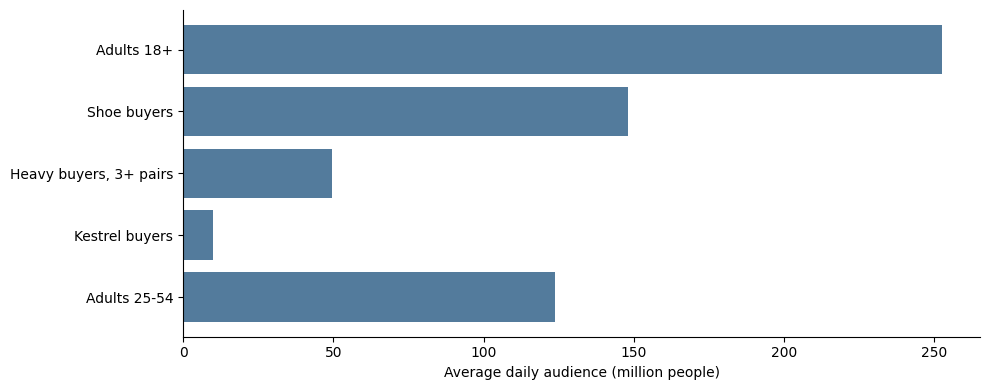

In [7]:
audience_ids = {
    "Adults 18+": adults.index,
    "Shoe buyers": purchases.index[purchases.buyer],
    "Heavy buyers, 3+ pairs": purchases.index[purchases.pairs.eq("3+")],
    "Kestrel buyers": purchases.index[purchases.KESTREL],
    "Adults 25-54": adults.index[adults.age.between(25, 54)]
}
weights = daily_weights.loc[daily_weights.resp_type.isin(["R", "L"]) &
                            daily_weights.broadcast_date.isin(days)].copy()

def daily_size(ids):
    return (weights.loc[weights.respondent_id.isin(ids)]
            .groupby("broadcast_date").weight.sum().reindex(days, fill_value=0))

sizes = {name: daily_size(ids).mean() for name, ids in audience_ids.items()}
for name, size in sizes.items():
    print(f"{name} (M):", f"{size/1e6:.1f}")
print("Kestrel buyers in panel (n):", int(purchases.KESTREL.sum()))

plt.barh(list(sizes), np.array(list(sizes.values()))/1e6, color="#537b9c")
plt.xlabel("Average daily audience (million people)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Task 1.2 — Who are they?

I use the five groups listed in the task: three age groups and two sexes.

In [8]:
groups = {
    "18-34": adults.index[adults.age.between(18, 34)],
    "35-54": adults.index[adults.age.between(35, 54)],
    "55+": adults.index[adults.age.ge(55)],
    "Men": adults.index[adults.sex.eq("Male")],
    "Women": adults.index[adults.sex.eq("Female")]
}
profile_rows = []
for name, ids in audience_ids.items():
    for group, group_ids in groups.items():
        # Ratio of average daily sums, using the same 31 broadcast days.
        share = daily_size(ids.intersection(group_ids)).mean() / sizes[name]
        adult_share = daily_size(group_ids).mean() / sizes["Adults 18+"]
        profile_rows.append([name, group, share, share/adult_share*100])
profiles = pd.DataFrame(profile_rows, columns=["Audience", "Group", "Share", "Index vs adults"])
display(profiles.style.hide(axis="index").format({"Share": "{:.3f}", "Index vs adults": "{:.1f}"}))

Audience,Group,Share,Index vs adults
Adults 18+,18-34,0.288,100.0
Adults 18+,35-54,0.319,100.0
Adults 18+,55+,0.393,100.0
Adults 18+,Men,0.488,100.0
Adults 18+,Women,0.512,100.0
Shoe buyers,18-34,0.281,97.5
Shoe buyers,35-54,0.336,105.3
Shoe buyers,55+,0.383,97.5
Shoe buyers,Men,0.485,99.3
Shoe buyers,Women,0.515,100.7


**Answer:** I would use heavy buyers because this matches Kestrel's brief and gives a larger sample than Kestrel buyers alone. Adults 25-54 include many people who do not buy heavily and leave out heavy buyers outside that age range. Heavy buyers lean towards women and ages 35-54, while Kestrel buyers have an even stronger 35-54 skew. Shoe buyers have a similar profile to all adults because buying athletic shoes is common across age and sex groups. A fused purchase attribute cannot show that people prefer a program independently of the demographics used to assign that attribute.

## Task 2.1 — Programs by audience

I calculate average-minute viewers from weighted viewing minutes. Each telecast's rating uses that day's in-tab audience size, and program results are the mean of its October prime-time telecasts.

In [9]:
person_viewings = viewings.loc[viewings.resp_type.isin(["R", "L"]),
                               ["respondent_id", "network_code", "start_ts", "end_ts"]]
viewing_groups = {key: part for key, part in person_viewings.groupby("network_code")}
weight_days = {day: part.set_index("respondent_id").weight
               for day, part in weights.groupby("broadcast_date")}
rating_ids = {"p2": people.index, "adult": adults.index,
              "heavy": audience_ids["Heavy buyers, 3+ pairs"],
              "kestrel": audience_ids["Kestrel buyers"]}
universes = {name: daily_size(ids) for name, ids in rating_ids.items()}

def rate_telecasts(schedule):
    rows = []
    for t in schedule.itertuples():
        sessions = viewing_groups[t.network_code]
        overlap = sessions.loc[(sessions.start_ts < t.end_ts) &
                               (sessions.end_ts > t.start_ts)].copy()
        minutes = ((overlap.end_ts.clip(upper=t.end_ts) -
                    overlap.start_ts.clip(lower=t.start_ts)).dt.total_seconds()/60)
        day_weights = weight_days[t.broadcast_date]
        weighted_minutes = minutes * overlap.respondent_id.map(day_weights).fillna(0)
        row = {"telecast_id": t.telecast_id}
        for name, ids in rating_ids.items():
            mask = overlap.respondent_id.isin(ids)
            viewers = weighted_minutes.loc[mask].sum() / t.duration_min
            row[name + "_viewers"] = viewers
            row[name + "_rating"] = viewers / universes[name].loc[t.broadcast_date] * 100
        rows.append(row)
    return schedule.merge(pd.DataFrame(rows), on="telecast_id", validate="one_to_one")

prime = programs.loc[programs.daypart.eq("Prime") & programs.broadcast_date.isin(days)].copy()
ratings = rate_telecasts(prime)

In [10]:
# A program price takes priority over the network's time prices.
def clock_minute(text):
    hour, minute = map(int, text.split(":"))
    return hour*60 + minute

def price_telecast(t):
    network_rows = rate_card.loc[rate_card.network_code.eq(t.network_code)]
    program_rows = network_rows.loc[network_rows.program_name.eq(t.program_name)]
    if len(program_rows):
        return int(program_rows.iloc[0].cost_30s_usd)
    clock = t.start_ts.hour*60 + t.start_ts.minute
    if clock < 360:
        clock += 1440
    time_rows = network_rows.loc[network_rows.program_name.isna()]
    matches = [r.cost_30s_usd for r in time_rows.itertuples()
               if t.broadcast_date.weekday() in r.weekdays
               and clock_minute(r.start_time) <= clock < clock_minute(r.end_time)]
    assert len(matches) == 1
    return int(matches[0])

In [11]:
requested = [
    ("NBC", "NFL Football", "Sunday Night Football (NBC)"),
    ("ABC", "NFL Football", "Monday Night Football (ABC)"),
    ("ABC", "Dancing with the Stars", "Dancing with the Stars (ABC)"),
    ("CBS", "NCIS", "NCIS (CBS)"),
    ("FNC", "Hannity", "Hannity (FNC)"),
    ("HGTV", "Unsellable Houses", "Unsellable Houses (HGTV)"),
    ("FOOD", "Halloween Wars", "Halloween Wars (FOOD)"),
    ("FX", "Grotesquerie", "Grotesquerie (FX)")
]
program_rows = []
for network, name, label in requested:
    telecasts = ratings.loc[ratings.network_code.eq(network) & ratings.program_name.eq(name)].copy()
    telecasts["cost"] = [price_telecast(t) for t in telecasts.itertuples()]
    avg = telecasts.select_dtypes("number").mean()
    program_rows.append({
        "Program": label, "Telecasts": len(telecasts),
        "Adults rating": avg.adult_rating, "Target rating": avg.heavy_rating,
        "Target viewers (000)": avg.heavy_viewers/1000,
        "Composition": avg.heavy_viewers/avg.adult_viewers,
        "Index": avg.heavy_rating/avg.adult_rating*100,
        "Cost per :30": avg.cost,
        "Adults CPM": avg.cost/avg.adult_viewers*1000,
        "Target CPM": avg.cost/avg.heavy_viewers*1000,
        "Kestrel index": avg.kestrel_rating/avg.adult_rating*100,
        "Adult viewers": avg.adult_viewers, "Target viewers": avg.heavy_viewers
    })
program_table = pd.DataFrame(program_rows).set_index("Program")
formats = {"Adults rating": "{:.2f}", "Target rating": "{:.2f}",
           "Target viewers (000)": "{:.1f}", "Composition": "{:.3f}",
           "Index": "{:.1f}", "Cost per :30": "{:.0f}",
           "Adults CPM": "{:.0f}", "Target CPM": "{:.0f}"}
display(program_table[list(formats)].style.format(formats))
print("Target universe (M):", f"{sizes['Heavy buyers, 3+ pairs']/1e6:.1f}")

,Adults rating,Target rating,Target viewers (000),Composition,Index,Cost per :30,Adults CPM,Target CPM
Program,,,,,,,,
Sunday Night Football (NBC),5.82,5.79,2865.0,0.195,99.3,487200,33,170
Monday Night Football (ABC),8.93,8.36,4149.1,0.184,93.6,723600,32,174
Dancing with the Stars (ABC),3.25,3.14,1564.2,0.191,96.8,158600,19,101
NCIS (CBS),2.21,2.43,1206.3,0.216,110.1,178800,32,148
Hannity (FNC),1.09,0.84,416.9,0.152,77.1,39900,15,96
Unsellable Houses (HGTV),0.50,0.64,317.2,0.249,126.8,12900,10,41
Halloween Wars (FOOD),0.28,0.33,161.9,0.228,116.2,9700,14,60
Grotesquerie (FX),0.26,0.25,124.2,0.188,95.9,7592,11,61


Target universe (M): 49.6


## Task 2.2 — Index, volume or price?

In [12]:
print("Highest index (program):", program_table.Index.idxmax())
print("Most target viewers (program):", program_table["Target viewers"].idxmax())
print("Lowest target CPM (program):", program_table["Target CPM"].idxmin())

Highest index (program): Unsellable Houses (HGTV)
Most target viewers (program): Monday Night Football (ABC)
Lowest target CPM (program): Unsellable Houses (HGTV)


**Answer:** Unsellable Houses has the highest index, 126.8, and the lowest target CPM, about 41 dollars. Monday Night Football delivers the most target viewers, about 4.1 million per spot, so the three choices are not all the same program. I would tell the client that index measures concentration, while CPM measures cost efficiency and viewer numbers measure volume. As in the shampoo example, buying only the highest index can leave out many potential buyers, so I would consider all three measures.

## Task 2.3 — Kestrel buyers

In [13]:
display(program_table[["Index", "Kestrel index"]]
        .rename(columns={"Index": "Heavy-buyer index"}).style.format("{:.1f}"))

sample_rows = []
for network, name, label in requested:
    show = prime.loc[prime.network_code.eq(network) & prime.program_name.eq(name)]
    counts = {"heavy": [], "kestrel": []}
    for t in show.itertuples():
        v = viewing_groups[network]
        ids = v.loc[(v.start_ts < t.end_ts) & (v.end_ts > t.start_ts), "respondent_id"]
        ids = pd.Index(ids.unique()).intersection(weight_days[t.broadcast_date].index)
        for audience in counts:
            counts[audience].append(len(ids.intersection(rating_ids[audience])))
    sample_rows.append([label, np.mean(counts["heavy"]), np.mean(counts["kestrel"])])
display(pd.DataFrame(sample_rows, columns=["Program", "Heavy viewers in panel (mean n)",
                                          "Kestrel viewers in panel (mean n)"])
        .style.hide(axis="index").format({"Heavy viewers in panel (mean n)": "{:.1f}",
                                         "Kestrel viewers in panel (mean n)": "{:.1f}"}))

,Heavy-buyer index,Kestrel index
Program,,
Sunday Night Football (NBC),99.3,98.5
Monday Night Football (ABC),93.6,85.9
Dancing with the Stars (ABC),96.8,82.7
NCIS (CBS),110.1,56.5
Hannity (FNC),77.1,42.6
Unsellable Houses (HGTV),126.8,76.9
Halloween Wars (FOOD),116.2,95.2
Grotesquerie (FX),95.9,129.6


Program,Heavy viewers in panel (mean n),Kestrel viewers in panel (mean n)
Sunday Night Football (NBC),329.0,75.2
Monday Night Football (ABC),292.7,69.3
Dancing with the Stars (ABC),122.6,23.4
NCIS (CBS),86.3,11.0
Hannity (FNC),15.9,2.1
Unsellable Houses (HGTV),25.4,4.0
Halloween Wars (FOOD),13.7,2.8
Grotesquerie (FX),11.4,3.1


**Answer:** There are only 354 Kestrel buyers in the panel, compared with 1661 heavy buyers. The smaller programs often have just two to four Kestrel viewers per telecast, so one person and their weight can change the index a lot. Some differences also come from the brand's demographic profile. I would trust the heavy-buyer index more, but I would still check the viewer counts and compare the indexes across weeks before using a small program's result.

## Task 3.1 — Weights

In [14]:
# A match requires exactly one household for this IP.
ip_counts = hh_attributes.groupby("hashed_ip").household_id.nunique()
one_home = hh_attributes.loc[hh_attributes.hashed_ip.map(ip_counts).eq(1)].drop_duplicates("hashed_ip")
tvs = acr_sessions[["tv_id", "hashed_ip"]].drop_duplicates()
assert tvs.tv_id.is_unique
matched_tvs = tvs.merge(one_home, on="hashed_ip", how="inner", validate="many_to_one")
matched_tvs["head_age"] = np.where(matched_tvs.head_age_band.eq("65+"), "65+", "Under 65")

# Edit first; any surviving session makes the TV in-tab.
long_enough = (acr_sessions.end_utc - acr_sessions.start_utc).dt.total_seconds().ge(60)
acr = acr_sessions.loc[long_enough, ["tv_id", "session_type", "network_code", "start_utc", "end_utc"]].copy()
acr["start_ts"] = acr.start_utc.dt.tz_convert("America/New_York").dt.tz_localize(None)
acr["end_ts"] = acr.end_utc.dt.tz_convert("America/New_York").dt.tz_localize(None)
acr["broadcast_date"] = (acr.start_ts - pd.Timedelta(hours=6)).dt.normalize()
acr = acr.drop(columns=["start_utc", "end_utc"])
del acr_sessions

In [15]:
# Keep the next day too when an edited session crosses 06:00.
last_day = (acr.end_ts - pd.Timedelta(hours=6, microseconds=1)).dt.normalize()
extra_days = acr.loc[last_day.ne(acr.broadcast_date), ["tv_id"]].copy()
extra_days["broadcast_date"] = last_day
all_tv_days = pd.concat([acr[["tv_id", "broadcast_date"]], extra_days]).drop_duplicates()
all_tv_days = all_tv_days.loc[all_tv_days.broadcast_date.between("2024-10-14", "2024-10-27")]
in_tab = all_tv_days.merge(
    matched_tvs[["tv_id", "head_age", "income_band"]], on="tv_id", validate="many_to_one")
cell_cols = ["broadcast_date", "head_age", "income_band"]
cell_n = in_tab.groupby(cell_cols).size().rename("TVs in cell").reset_index()
cell_n = cell_n.merge(universe, on=["head_age", "income_band"], validate="many_to_one")
cell_n["cell_weight"] = cell_n.tv_households / cell_n["TVs in cell"]
in_tab = in_tab.merge(cell_n[cell_cols + ["cell_weight"]], on=cell_cols, validate="many_to_one")
weight_sums = in_tab.groupby("broadcast_date").cell_weight.sum()
assert cell_n.groupby("broadcast_date").size().eq(12).all()
assert np.allclose(weight_sums, universe.tv_households.sum())

print("TVs matched to one household:", len(matched_tvs))
print("Weights sum per day (M):", ", ".join(f"{x/1e6:.1f}" for x in weight_sums))
weight_check = (weight_sums/1e6).rename("Weights sum (M)").to_frame()
weight_check.index = weight_check.index.strftime("%Y-%m-%d")
display(weight_check.style.format("{:.1f}"))

refs = reference_ratings.merge(programs, on="telecast_id", validate="one_to_one")
live = acr.loc[acr.session_type.eq("live") & acr.tv_id.isin(matched_tvs.tv_id)]
smart_rows = []
for t in refs.itertuples():
    v = live.loc[live.network_code.eq(t.network_code) &
                 (live.start_ts < t.end_ts) & (live.end_ts > t.start_ts)].copy()
    v["minutes"] = ((v.end_ts.clip(upper=t.end_ts) -
                     v.start_ts.clip(lower=t.start_ts)).dt.total_seconds()/60)
    watched = v.groupby("tv_id").minutes.sum().loc[lambda x: x.ge(1)].index
    eligible = in_tab.loc[in_tab.broadcast_date.eq(t.broadcast_date)].set_index("tv_id")
    saw = eligible.index.isin(watched)
    # Age-only and income-only results help explain which cells matter.
    age_n = eligible.groupby("head_age").size()
    income_n = eligible.groupby("income_band").size()
    age_target = universe.groupby("head_age").tv_households.sum()
    income_target = universe.groupby("income_band").tv_households.sum()
    age_weights = eligible.head_age.map(age_target/age_n)
    income_weights = eligible.income_band.map(income_target/income_n)
    smart_rows.append({"Program": f"{t.program_name} ({t.network_code})",
                       "Date": t.broadcast_date.strftime("%Y-%m-%d"),
                       "Unweighted": saw.mean()*100,
                       "Weighted": eligible.loc[saw, "cell_weight"].sum()/eligible.cell_weight.sum()*100,
                       "Reference": t.hh_rating,
                       "Age only": age_weights.loc[saw].sum()/age_weights.sum()*100,
                       "Income only": income_weights.loc[saw].sum()/income_weights.sum()*100})
smart_ratings = pd.DataFrame(smart_rows)
display(smart_ratings[["Program", "Date", "Unweighted", "Weighted", "Reference"]]
        .style.hide(axis="index").format({c: "{:.2f}" for c in ["Unweighted", "Weighted", "Reference"]}))
gap_raw = (smart_ratings.Unweighted-smart_ratings.Reference).abs().mean()
gap_weighted = (smart_ratings.Weighted-smart_ratings.Reference).abs().mean()
print("Mean gap unweighted (points):", f"{gap_raw:.2f}")
print("Mean gap weighted (points):", f"{gap_weighted:.2f}")
print("Share of gap closed:", f"{(gap_raw-gap_weighted)/gap_raw:.3f}")

TVs matched to one household: 19607
Weights sum per day (M): 125.8, 125.8, 125.8, 125.8, 125.8, 125.8, 125.8, 125.8, 125.8, 125.8, 125.8, 125.8, 125.8, 125.8


,Weights sum (M)
broadcast_date,
2024-10-14,125.8
2024-10-15,125.8
2024-10-16,125.8
2024-10-17,125.8
2024-10-18,125.8
2024-10-19,125.8
2024-10-20,125.8
2024-10-21,125.8
2024-10-22,125.8


Program,Date,Unweighted,Weighted,Reference
MLB Postseason (FOX),2024-10-25,17.03,17.76,25.86
NFL Football (NBC),2024-10-27,22.62,23.75,33.14
NCIS (CBS),2024-10-14,5.50,5.80,10.56
Hannity (FNC),2024-10-16,1.04,1.35,2.30
Unsellable Houses (HGTV),2024-10-16,2.12,2.08,3.69
Halloween Baking Championship (FOOD),2024-10-14,0.95,0.90,1.63
Grotesquerie (FX),2024-10-16,2.17,2.11,3.53
The Real Housewives of New York City (BRAVO),2024-10-15,0.71,0.64,1.23


Mean gap unweighted (points): 3.73
Mean gap weighted (points): 3.44
Share of gap closed: 0.075


In [16]:
# Compare the footprint profile with the targets and isolate income weighting.
profile = in_tab.groupby("head_age").size()/len(in_tab)
target_profile = universe.groupby("head_age").tv_households.sum()/universe.tv_households.sum()
display(pd.DataFrame({"Footprint share": profile, "Universe share": target_profile})
        .style.format("{:.3f}"))
display(smart_ratings[["Program", "Unweighted", "Age only", "Income only", "Weighted"]]
        .style.hide(axis="index").format({c: "{:.2f}" for c in ["Unweighted", "Age only", "Income only", "Weighted"]}))

,Footprint share,Universe share
head_age,,
65+,0.194,0.283
Under 65,0.806,0.717


Program,Unweighted,Age only,Income only,Weighted
MLB Postseason (FOX),17.03,17.95,16.85,17.76
NFL Football (NBC),22.62,23.98,22.44,23.75
NCIS (CBS),5.50,5.84,5.45,5.80
Hannity (FNC),1.04,1.31,1.08,1.35
Unsellable Houses (HGTV),2.12,2.15,2.06,2.08
Halloween Baking Championship (FOOD),0.95,0.95,0.91,0.90
Grotesquerie (FX),2.17,2.15,2.11,2.11
The Real Housewives of New York City (BRAVO),0.71,0.67,0.68,0.64


## Task 3.2 — What weighting cannot fix

**Answer:** Weighting raises the ratings for football, baseball, NCIS and Hannity, while the four smaller cable programs move slightly down. Older homes are under-represented in the footprint, so increasing their weights helps programs with older audiences. The mean gap falls from 3.73 to 3.44 points, closing only 7.5% of it. Weights cannot recover viewing on other sets or unidentified content, and they cannot remove all opt-in, missing-session and IP-matching bias. Income-only weighting changes these ratings by less than 0.2 points: income is less closely related to these programs' viewing than age, and balancing it cannot restore missing viewing.

## Task 4.1 — October predicts October

In [17]:
big_networks = ["CBS", "NBC", "ABC", "FOX", "FNC"]
history = ratings.loc[ratings.network_code.isin(big_networks) &
                      ratings.broadcast_date.between("2024-10-01", "2024-10-21")]
future = ratings.loc[ratings.network_code.isin(big_networks) &
                     ratings.broadcast_date.between("2024-10-22", "2024-10-28")]
keys = ["network_code", "program_name"]
history_means = (history.groupby(keys)[["p2_rating", "heavy_rating"]].mean()
                 .rename(columns={"p2_rating": "p2_forecast", "heavy_rating": "heavy_forecast"}))
forecasts = future.merge(history_means, on=keys, how="inner", validate="many_to_one")
for audience in ["p2", "heavy"]:
    actual = forecasts[audience + "_rating"]
    forecasts[audience + "_error"] = (actual - forecasts[audience + "_forecast"]).abs().div(actual.where(actual.gt(0)))
mape_p2 = forecasts.p2_error.mean()*100
mape_heavy = forecasts.heavy_error.mean()*100
worst = forecasts.nlargest(1, "p2_error").iloc[0]
print("Telecasts forecast (n):", len(forecasts))
print("MAPE, P2+ (%):", f"{mape_p2:.1f}")
print("MAPE, heavy buyers (%):", f"{mape_heavy:.1f}")
print("Biggest miss, P2+ (program, date):",
      f"{worst.program_name} ({worst.network_code}), {worst.broadcast_date:%Y-%m-%d}")
print("Non-zero actuals, P2+ (n):", forecasts.p2_error.notna().sum())
print("Non-zero actuals, heavy buyers (n):", forecasts.heavy_error.notna().sum())

# Keep the error of every eligible forecast visible.
forecast_display = forecasts[["program_name", "network_code", "broadcast_date", "p2_forecast",
                              "p2_rating", "p2_error", "heavy_forecast", "heavy_rating", "heavy_error"]].copy()
forecast_display["Program"] = forecast_display.program_name + " (" + forecast_display.network_code + ")"
forecast_display["Date"] = forecast_display.broadcast_date.dt.strftime("%Y-%m-%d")
forecast_display["P2+ error (%)"] = forecast_display.p2_error*100
forecast_display["Heavy error (%)"] = forecast_display.heavy_error*100
forecast_display = forecast_display.rename(columns={"p2_forecast": "P2+ forecast", "p2_rating": "P2+ actual",
                                                     "heavy_forecast": "Heavy forecast", "heavy_rating": "Heavy actual"})
display(forecast_display[["Program", "Date", "P2+ forecast", "P2+ actual", "P2+ error (%)",
                          "Heavy forecast", "Heavy actual", "Heavy error (%)"]]
        .style.hide(axis="index").format({"P2+ forecast": "{:.2f}", "P2+ actual": "{:.2f}",
                                         "P2+ error (%)": "{:.1f}", "Heavy forecast": "{:.2f}",
                                         "Heavy actual": "{:.2f}", "Heavy error (%)": "{:.1f}"}, na_rep="skipped"))

Telecasts forecast (n): 101
MAPE, P2+ (%): 35.8
MAPE, heavy buyers (%): 38.6
Biggest miss, P2+ (program, date): Krapopolis (FOX), 2024-10-27
Non-zero actuals, P2+ (n): 101
Non-zero actuals, heavy buyers (n): 101


Program,Date,P2+ forecast,P2+ actual,P2+ error (%),Heavy forecast,Heavy actual,Heavy error (%)
Dancing with the Stars (ABC),2024-10-22,2.75,2.79,1.2,3.00,3.68,18.5
High Potential (ABC),2024-10-22,1.01,1.00,1.1,1.24,1.31,5.9
The Golden Bachelorette (ABC),2024-10-23,1.26,0.79,60.4,1.45,1.05,38.3
Abbott Elementary (ABC),2024-10-23,1.10,0.60,84.9,1.27,0.51,151.6
What Would You Do? (ABC),2024-10-23,0.44,0.18,138.1,0.34,0.11,202.4
9-1-1 (ABC),2024-10-24,1.34,1.09,22.4,1.46,1.24,17.3
Doctor Odyssey (ABC),2024-10-24,1.18,0.90,31.0,1.20,1.40,14.3
Grey's Anatomy (ABC),2024-10-24,2.11,2.38,11.3,2.30,3.07,24.9
Shark Tank (ABC),2024-10-25,2.16,2.45,11.7,2.23,2.98,25.3
Lucky 13 (ABC),2024-10-25,0.89,1.69,47.6,1.00,2.36,57.4


## Task 4.2 — Why it missed

In [18]:
misses = forecasts.nlargest(5, "p2_error").copy()
misses["Program"] = misses.program_name + " (" + misses.network_code + ")"
misses["Date"] = misses.broadcast_date.dt.strftime("%Y-%m-%d")
misses["Error (%)"] = misses.p2_error*100
display(misses[["Program", "Date", "p2_forecast", "p2_rating", "Error (%)"]]
        .rename(columns={"p2_forecast": "Forecast", "p2_rating": "Actual"})
        .style.hide(axis="index").format({"Forecast": "{:.2f}", "Actual": "{:.2f}", "Error (%)": "{:.1f}"}))

# Show the actual schedule around the misses instead of guessing the reason.
context = []
for t in misses.itertuples():
    schedule = programs.loc[programs.network_code.eq(t.network_code) &
                            programs.broadcast_date.eq(t.broadcast_date)].sort_values("start_ts")
    position = list(schedule.telecast_id).index(t.telecast_id)
    for offset in [-1, 0, 1]:
        if 0 <= position+offset < len(schedule):
            row = schedule.iloc[position+offset]
            context.append([t.broadcast_date.strftime("%Y-%m-%d"), t.network_code,
                            ["Previous", "Miss", "Next"][offset+1], row.start_ts.strftime("%H:%M"),
                            row.program_name, row.episode_name, row.is_repeat])
display(pd.DataFrame(context, columns=["Date", "Network", "Position", "Start", "Program", "Episode", "Repeat"]))

# Broader Sunday schedule: football and the shifted CBS line-up.
sunday_context = programs.loc[
    programs.broadcast_date.eq("2024-10-27") & programs.network_code.isin(["CBS", "NBC", "FOX"]) &
    programs.start_ts.dt.hour.between(16, 22),
    ["network_code", "start_ts", "end_ts", "program_name", "episode_name", "is_repeat"]].copy()
sunday_context["start_ts"] = sunday_context.start_ts.dt.strftime("%H:%M")
sunday_context["end_ts"] = sunday_context.end_ts.dt.strftime("%H:%M")
display(sunday_context.reset_index(drop=True))

# The history shows which slots and repeats went into each mean.
history_context = history.merge(misses[keys].drop_duplicates(), on=keys)
history_context["Date"] = history_context.broadcast_date.dt.strftime("%Y-%m-%d")
history_context["Time"] = history_context.start_ts.dt.strftime("%H:%M")
display(history_context[["program_name", "network_code", "Date", "Time", "is_repeat", "p2_rating"]]
        .rename(columns={"program_name": "Program", "network_code": "Network", "is_repeat": "Repeat",
                         "p2_rating": "History P2+ rating"}).style.hide(axis="index")
        .format({"History P2+ rating": "{:.2f}"}))

Program,Date,Forecast,Actual,Error (%)
Krapopolis (FOX),2024-10-27,1.06,0.22,387.8
Universal Basic Guys (FOX),2024-10-27,0.68,0.26,162.2
Fire Country (CBS),2024-10-27,1.70,0.67,154.8
Accused (FOX),2024-10-22,0.95,0.37,154.6
What Would You Do? (ABC),2024-10-23,0.44,0.18,138.1


,Date,Network,Position,Start,Program,Episode,Repeat
0,2024-10-27,FOX,Previous,21:00,Bob's Burgers,For Whom the Doll Toes,False
1,2024-10-27,FOX,Miss,21:30,Krapopolis,Mr. Boogens,False
2,2024-10-27,FOX,Next,22:00,Bob's Burgers,None,True
3,2024-10-27,FOX,Previous,20:00,The Simpsons,Shoddy Heat,False
4,2024-10-27,FOX,Miss,20:30,Universal Basic Guys,Fight or Flight,False
5,2024-10-27,FOX,Next,21:00,Bob's Burgers,For Whom the Doll Toes,False
6,2024-10-27,CBS,Previous,21:44,The Equalizer,Haunted Heights,False
7,2024-10-27,CBS,Miss,22:44,Fire Country,None,True
8,2024-10-27,CBS,Next,23:00,Local / Syndicated Programming,None,False
9,2024-10-22,FOX,Previous,20:00,Murder in a Small Town,A Touch of Panic,False


,network_code,start_ts,end_ts,program_name,episode_name,is_repeat
0,CBS,16:10,16:25,Local / Syndicated Programming,None,False
1,CBS,16:25,19:35,NFL Football,Chicago Bears at Washington Commanders,False
2,CBS,19:35,20:00,60 Minutes,Deportation | Sanctions | Surfmen,False
3,CBS,20:00,20:30,Poppa's House,None,True
4,CBS,20:30,20:44,Fire Country,None,True
5,CBS,20:44,21:44,Tracker,Bloodlines,False
6,CBS,21:44,22:44,The Equalizer,Haunted Heights,False
7,CBS,22:44,23:00,Fire Country,None,True
8,FOX,16:05,19:15,NFL Football,NFL Football: regional coverage (2 games),False
9,FOX,19:15,20:00,Local / Syndicated Programming,None,False


Program,Network,Date,Time,Repeat,History P2+ rating
What Would You Do?,ABC,2024-10-07,22:00,False,0.49
What Would You Do?,ABC,2024-10-16,22:00,False,0.38
Fire Country,CBS,2024-10-18,21:00,False,1.81
Fire Country,CBS,2024-10-19,21:00,True,1.58
Accused,FOX,2024-10-01,21:00,True,1.87
Krapopolis,FOX,2024-10-02,22:00,True,1.76
Universal Basic Guys,FOX,2024-10-06,20:30,False,0.26
Krapopolis,FOX,2024-10-06,21:30,False,0.26
Accused,FOX,2024-10-08,21:00,False,0.61
Krapopolis,FOX,2024-10-09,22:00,True,1.93


**Answer:** Krapopolis' history mean was raised by high-rated Wednesday repeats, while Universal Basic Guys changed from its 20:00 slot on 2024-10-20 to 20:30 on 2024-10-27. That Sunday also had NFL games and a shifted CBS schedule; the missed Fire Country telecast was a short repeat at 22:44. Accused's forecast was pulled up by a high-rated repeat on 2024-10-01, while What Would You Do? fell below both its history ratings after Abbott Elementary. These examples show why a program mean can miss changes in episodes, time slots and lead-ins, although the schedule alone does not prove the cause. Heavy buyers have fewer in-target panelists, which makes their ratings noisier and helps explain their higher MAPE, 38.6% versus 35.8%. I would add repeat and time-slot information, plus lead-in ratings and competing sports or specials; small actual ratings also make MAPE especially large.

## Task 5.1 — The plan

In [19]:
# Whole :30 spots. The price and delivery of each spot are the Task 2 averages.
spot_counts = {
    "Sunday Night Football (NBC)": 1,
    "Dancing with the Stars (ABC)": 2,
    "Unsellable Houses (HGTV)": 9,
    "Halloween Wars (FOOD)": 5,
    "Grotesquerie (FX)": 4
}
plan = program_table.loc[list(spot_counts), ["Cost per :30", "Target viewers", "Adult viewers", "Composition"]].copy()
plan["Spots"] = pd.Series(spot_counts)
plan["Cost"] = plan["Spots"] * plan["Cost per :30"]
plan["Target impressions"] = plan["Spots"] * plan["Target viewers"]
plan["Adult impressions"] = plan["Spots"] * plan["Adult viewers"]
plan["Cost outside target"] = plan["Cost"] * (1-plan["Composition"])
plan_cost = plan.Cost.sum()
plan_impressions = plan["Target impressions"].sum()
plan_composition = plan_impressions / plan["Adult impressions"].sum()
outside_cost = plan["Cost outside target"].sum()
assert plan_cost <= 1_000_000 and plan.Spots.ge(0).all()
assert plan.Spots.mod(1).eq(0).all()

display(plan[["Spots", "Cost per :30", "Cost", "Target impressions"]]
        .style.format({"Spots": "{:.0f}", "Cost per :30": "{:.0f}", "Cost": "{:.0f}", "Target impressions": "{:.0f}"}))
print("Plan cost ($):", f"{plan_cost:.0f}")
print("Plan target impressions (M):", f"{plan_impressions/1e6:.1f}")
print("Budget left ($):", f"{1_000_000-plan_cost:.0f}")
print("Plan target CPM ($):", f"{plan_cost/plan_impressions*1000:.0f}")
print("Plan composition:", f"{plan_composition:.3f}")
print("Adult impressions outside target (share):", f"{1-plan_composition:.3f}")
print("Cost allocated outside target ($):", f"{outside_cost:.0f}")
print("Cost allocated outside target (share):", f"{outside_cost/plan_cost:.3f}")

,Spots,Cost per :30,Cost,Target impressions
Program,,,,
Sunday Night Football (NBC),1,487200,487200,2865049
Dancing with the Stars (ABC),2,158600,317200,3128463
Unsellable Houses (HGTV),9,12900,116100,2855219
Halloween Wars (FOOD),5,9700,48500,809631
Grotesquerie (FX),4,7592,30368,496942


Plan cost ($): 999368
Plan target impressions (M): 10.2
Budget left ($): 632
Plan target CPM ($): 98
Plan composition: 0.208
Adult impressions outside target (share): 0.792
Cost allocated outside target ($): 798362
Cost allocated outside target (share): 0.799


## Task 5.2 — Recommendation

**Answer:** I would buy the spot mix in the table for 999368 dollars, leaving 632 dollars of the budget. It is estimated to deliver 10.2 million heavy-buyer impressions at a target CPM of about 98 dollars. Unsellable Houses gives the best target CPM and index, football adds volume, and the other programs spread delivery across different audiences. This assumes November availability at October average costs, and the impressions include repeat exposures. The heavy-buyer MAPE is 38.6%, so I would treat delivery cautiously and discuss guarantees and make-goods. Using adult-based composition, 0.792 of adult impressions are outside the target, and allocating each program's cost by composition puts about 798362 dollars outside it. After the week, I would compare actual target impressions, CPM, composition, reach and frequency with the plan and check any guaranteed shortfall.